---
title: "Minority Language Survival Under the Pressure of 2026 Globalization and the AI Frontier"
subtitle: "Model catelog for subsequent data-driven narrative to be hosted on personal domain"
author: "Lila Gizzie"
date: today
format:
  html:
    code-fold: show
    toc: true
execute:
  execute: true
  echo: false
---

<!-- Cleaning data section -->

In [11]:
#| include: false
import plotly.express as px
import seaborn as sns
import pandas as pd
import numpy as np
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"

In [12]:
#| include: false

language_df = pd.read_csv("languages.csv")
language_df.head()

,ID,Name,Macroarea,Latitude,Longitude,Glottocode,ISO639P3code,Comment,Countries,ELCatMacroareas,classification,endangerment,code_authorities,codes,alt_names
0,10009,Wampanoag,NaN,41.702591,-73.319119,wamp1249,wam,Massachusett-Narragansett was a complex of Sou...,US,North America,Algic,awakening,ISO 639-3,wam,Wôpanâak; Massachusett-Narragansett; Massach...
1,1001,Xipaya,NaN,-4.390200,-53.964800,xipa1240,xiy,NaN,BR,South America,Tupian,dormant,ISO 639-3,xiy,Shipaja; Xipaia; Shipaya; Chipaia; Xipáya; Šip...
2,1002,Yuchi,NaN,36.000900,-96.098800,yuch1247,yuc,NaN,US,North America,Isolate,critically endangered,ISO 639-3,yuc,Euchee
3,10029,Suabo,NaN,-2.100000,132.197000,suab1238,szp,NaN,ID,Southeast Asia,Trans-New Guinea,critically endangered,ISO 639-3,szp,Suabau; Inanwatan; Mirabo; Iagu; Solowat; Itig...
4,1003,Wichita,NaN,35.064700,-98.278800,wich1260,wic,NaN,US,North America,Caddoan,dormant,ISO 639-3,wic,Witchita


In [13]:
#| include: false

language_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3465 entries, 0 to 3464
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                3465 non-null   int64  
 1   Name              3465 non-null   str    
 2   Macroarea         0 non-null      float64
 3   Latitude          3427 non-null   float64
 4   Longitude         3427 non-null   float64
 5   Glottocode        3379 non-null   str    
 6   ISO639P3code      3063 non-null   str    
 7   Comment           639 non-null    str    
 8   Countries         3454 non-null   str    
 9   ELCatMacroareas   3454 non-null   str    
 10  classification    3382 non-null   str    
 11  endangerment      3414 non-null   str    
 12  code_authorities  3357 non-null   str    
 13  codes             3391 non-null   str    
 14  alt_names         3025 non-null   str    
dtypes: float64(3), int64(1), str(11)
memory usage: 406.2 KB


In [14]:
#| include: false

language_df["endangerment"].unique()

<StringArray>
[            'awakening',               'dormant', 'critically endangered',
            'endangered',            'vulnerable',            'threatened',
   'severely endangered',               'at risk',                     nan]
Length: 9, dtype: str

<!-- Determining how many languages categorized as NaN endangerment level -->

In [15]:
#| include: false

nan_df = language_df.iloc[language_df["endangerment"].isna()]
len(nan_df)

51

In [16]:
#| include: false

palette = {
    "endangerment" : {
        'awakening': "#2e9e4f",             
        'vulnerable': "#f2d03b",           
        'at risk': "#a8c93a",               
        'threatened': "#f29a2e",           
        'endangered': "#e4572e",            
        'severely endangered': "#b3261e",   
        'critically endangered': "#6a1b2d", 
        'dormant': "#1a1a1a",               
        'nan': "#9aa0a6"                    
    },
    "main": {
        "black_forest": "#283618",
        "olive_leaf": "#606c38",
        "copper": "#bc6c25",
        "light_caramel": "#dda15e",
        "cornsilk": "#fefae0",
    },
    "extra": {
        "sage": "#a3b18a",
        "butter": "#efd27a",
        "rust": "#8f3b1b",
        "teal": "#3f7d78",
        "plum": "#7a4a5c",
        "stone": "#c9c7ae",
        "espresso": "#3a2a1a",
    }
}

In [17]:
legend_order = ["awakening", "at risk", "vulnerable", "threatened", "endangered", "severely endangered", "critically endangered", "dormant", "nan"]
fig = px.scatter_geo(
    language_df,
    lat = "Latitude",
    lon = "Longitude",
    labels = {"Name" : "Name", "Speakers" : ""},
    color = "endangerment",
    color_discrete_map=palette["endangerment"],
    width = 800,
    height = 500,
    category_orders = {"endangerment" : legend_order},
    hover_name="Name"
)

fig.update_layout(
    title = "Language Endangerment by Region",
    legend_title = "Degree of Endangerment",
    font_family = "Times New Roman"
)

fig.show()

In [18]:
#| include: false

language_df["ELCatMacroareas"].unique()

<StringArray>
[                                                               'North America',
                                                                'South America',
                                                               'Southeast Asia',
                                                                    'Near East',
                                                                       'Africa',
                                                  'Europe; Caucasus; East Asia',
                                                                      'Pacific',
                                                                    'East Asia',
                                                                    'Australia',
                                                                   'South Asia',
                                       'Europe; Caucasus; Near East; East Asia',
                                                                       'Europe',
              

In [19]:
#| include: false

print(language_df[language_df["ELCatMacroareas"] == 'Europe; North America'])

        ID         Name  Macroarea  Latitude  Longitude Glottocode  \
3359  8689  Kalaallisut        NaN    64.175 -51.738889   kala1399   

     ISO639P3code                                            Comment  \
3359          kal  There is a significant dialect difference betw...   

     Countries        ELCatMacroareas classification endangerment  \
3359     DK NC  Europe; North America   Eskimo-Aleut   vulnerable   

     code_authorities codes                                       alt_names  
3359        ISO 639-3   kal  Inuit; Eskimo; Greenlandic; Greenlandic Eskimo  


In [20]:
#| include: false

for i in range(0, len(language_df)):
    if language_df["ELCatMacroareas"][i] == 'North America':
            language_df["geo-region"][i] = 'North America'

KeyError: 'geo-region'

ValueError: Axes(0.125,0.11;0.775x0.77) has no legend attached.

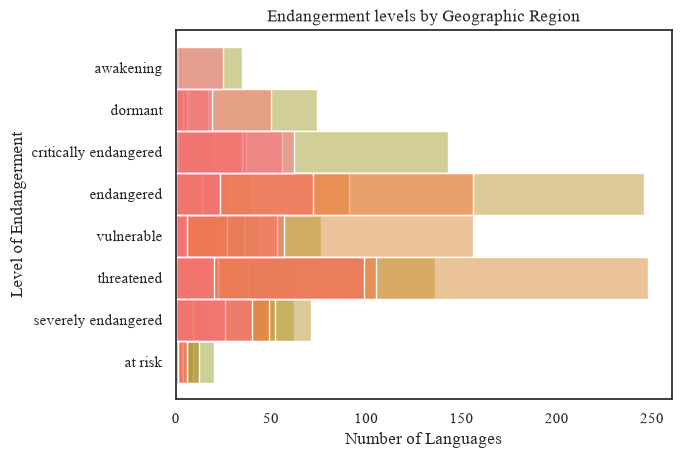

In [ ]:
#| include: false

sns.set_theme(style="white", font="Times New Roman")
ax = sns.histplot(language_df, y = "endangerment", hue="ELCatMacroareas", legend=False)
ax.set_title("Endangerment levels by Geographic Region")
ax.set_xlabel("Number of Languages")
ax.set_ylabel("Level of Endangerment")

sns.move_legend(ax, "lower left")

#ax.figure.savefig("wsoc1024.png", dpi=300, bbox_inches="tight")